# 05 · Deep-learning imputers on a Colab GPU
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mvya0005/mma3001-project-sensor-reconstruction/blob/main/notebooks/05_deep_learning_gpu.ipynb)

**Runtime → Change runtime type → T4 GPU** before running. Without a GPU the notebook switches to a `QUICK` configuration (fewer epochs and seeds) so that it still runs end-to-end on CPU, but the reported results should come from the GPU run.

| Model | Idea | Unit topic |
|---|---|---|
| **BiGRU imputer** | bidirectional recurrent network reads 3 days around a gap (values, mask, occupancy, calendar) and predicts the correction to linear interpolation | 5.4 neural-network regression |
| **Physics-informed BiGRU** | adds the CO₂ mass-balance residual $\dot C - [gN - \lambda(C - C_{out})]$ (finite differences on the output) to the loss, with *g*, λ, *C*<sub>out</sub> learned | 10.3 PINNs, 7.1 finite differences |
| **Neural ODE** | learns $\dot C = f_\theta(C, N, \text{time of day})$, integrated with a differentiable RK4; fills a gap as an IVP plus an end correction | 10.2 Neural ODEs, 7.4 RK4 |

Every model is selected on the **validation** period. The final test-period scores are exported to `reports/test_deep.csv` for notebook 06, using exactly the same artificial gaps as the other methods. They are not used for any choice here.

In [ ]:
# ---- Environment setup: works on Google Colab and locally ----
import os, sys, subprocess
from pathlib import Path

GITHUB_REPO = "mvya0005/mma3001-project-sensor-reconstruction"  # owner/name of this repository
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    repo_dir = Path("/content") / GITHUB_REPO.split("/")[1]
    if not repo_dir.exists():
        subprocess.run(["git", "clone", "-q", f"https://github.com/{GITHUB_REPO}.git", str(repo_dir)], check=True)
    os.chdir(repo_dir)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "."], check=True)
    sys.path.insert(0, str(repo_dir / "src"))  # editable install is not visible until restart
    from google.colab import drive
    drive.mount("/content/drive")
    RAW = Path("/content/drive/MyDrive/MMA3001/raw")              # put the two Moodle zip files here
    PROCESSED = Path("/content/drive/MyDrive/MMA3001/processed")  # cached across Colab sessions
else:
    if Path.cwd().name == "notebooks":
        os.chdir("..")
    sys.path.insert(0, str(Path("src").resolve()))
    RAW, PROCESSED = Path("data/raw"), Path("data/processed")

PROCESSED.mkdir(parents=True, exist_ok=True)
if not (PROCESSED / "audit.json").exists():
    subprocess.run([sys.executable, "scripts/preprocess.py", "--raw", str(RAW), "--out", str(PROCESSED)], check=True)
print("repository:", Path.cwd(), "| processed data:", PROCESSED)

Mounted at /content/drive
repository: /content/mma3001-project-sensor-reconstruction | processed data: /content/drive/MyDrive/MMA3001/processed


In [ ]:
import json, time
import numpy as np
import pandas as pd
import torch
from sensorfill import benchmark as bm, interpolation as itp, ode, profiling, study, plotting
from sensorfill.deep import BiGRUImputer, NeuralODE, get_device
from sensorfill.plotting import plt
plotting.setup()
device = get_device()
QUICK = device.type != "cuda"
print("device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "", "| QUICK mode:", QUICK)
CFG = dict(epochs=12 if QUICK else 60, steps=40 if QUICK else 150, batch=32 if QUICK else 128,
           seeds=(0,) if QUICK else (0, 1, 2), pw=(0.01,) if QUICK else (0.003, 0.01, 0.03, 0.1),
           node_epochs=8 if QUICK else 40)
MODEL_DIR = (PROCESSED.parent / "models") if IN_COLAB else Path("reports/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
s = study.load_study(PROCESSED, "co2")
(y_tr, ts_tr, o_tr), (y_v, ts_v, o_v), (y_te, ts_te, o_te) = s.part("train"), s.part("val"), s.part("test")
CFG

device: cuda Tesla T4 | QUICK mode: False


{'epochs': 60,
 'steps': 150,
 'batch': 128,
 'seeds': (0, 1, 2),
 'pw': (0.003, 0.01, 0.03, 0.1),
 'node_epochs': 40}

In [ ]:
# Physics parameters used to initialise the PINN (output-error fit, notebook 03)
h = study.DT_HOURS
yf, of = itp.fill_linear(y_tr), itp.fill_locf(o_tr)
segs = [(np.arange(144) * h, yf[i:i + 144], of[i:i + 144]) for i in range(0, len(yf) - 144, 144)]
p_ode, _ = ode.fit_output_error(segs, ode.fit_equation_error(yf, of, h))
print(p_ode)

CO2Params(g=np.float64(4.472410307568933), lam=np.float64(0.6291110189774027), c_out=np.float64(449.99463673521717), s=0.0)


## 1. BiGRU imputer: training (repeated over seeds for repeatability)

seed 0: 86 s, best epoch 1, best val loss 0.5559
seed 1: 89 s, best epoch 1, best val loss 0.5466
seed 2: 76 s, best epoch 0, best val loss 0.5252


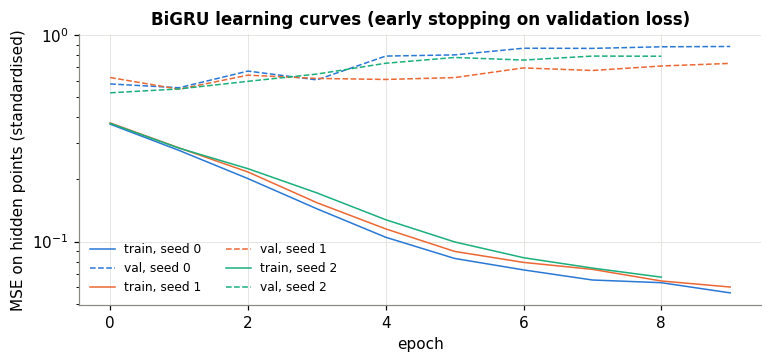

In [ ]:
gru_models, logs = {}, {}
for seed in CFG["seeds"]:
    m = BiGRUImputer(window=432, hidden=64, layers=2, dropout=0.1, device=device, seed=seed)
    logs[seed] = m.fit(y_tr, ts_tr, o_tr, y_v, ts_v, o_v, epochs=CFG["epochs"], steps_per_epoch=CFG["steps"], batch=CFG["batch"])
    gru_models[seed] = m
    torch.save(m.net.state_dict(), MODEL_DIR / f"bigru_seed{seed}.pt")
    print(f"seed {seed}: {logs[seed].seconds:.0f} s, best epoch {logs[seed].best_epoch}, best val loss {min(logs[seed].val_loss):.4f}")
fig, ax = plt.subplots(figsize=(8, 3.2))
for i, (seed, lg) in enumerate(logs.items()):
    ax.plot(lg.train_loss, color=plotting.PALETTE[i], lw=1, label=f"train, seed {seed}")
    ax.plot(lg.val_loss, color=plotting.PALETTE[i], ls="--", lw=1, label=f"val, seed {seed}")
ax.set_xlabel("epoch"); ax.set_ylabel("MSE on hidden points (standardised)"); ax.set_yscale("log"); ax.legend(ncol=2, fontsize=8)
ax.set_title("BiGRU learning curves (early stopping on validation loss)")
_ = plotting.save(fig, "05_gru_learning_curves")

## 2. Physics-informed variant: sweep of the physics-loss weight

In [ ]:
pinn_models = {}
for pw in CFG["pw"]:
    m = BiGRUImputer(window=432, hidden=64, layers=2, physics_weight=pw, ode_init=(p_ode.g, p_ode.lam, p_ode.c_out), device=device, seed=0)
    m.fit(y_tr, ts_tr, o_tr, y_v, ts_v, o_v, epochs=CFG["epochs"], steps_per_epoch=CFG["steps"], batch=CFG["batch"])
    pinn_models[pw] = m
    torch.save(m.net.state_dict(), MODEL_DIR / f"pinn_pw{pw}.pt")
    print(f"physics weight {pw}: learned params {m.physics_params}, best val loss {min(m.log.val_loss):.4f}")

physics weight 0.003: learned params {'g': 1.6189519166946411, 'lam': 0.17709645628929138, 'c_out': 448.5728759765625}, best val loss 0.5512
physics weight 0.01: learned params {'g': 1.5405329465866089, 'lam': 0.18243363499641418, 'c_out': 448.9691467285156}, best val loss 0.5489
physics weight 0.03: learned params {'g': 1.5408865213394165, 'lam': 0.1901044398546219, 'c_out': 449.1866455078125}, best val loss 0.5325
physics weight 0.1: learned params {'g': 1.7567001581192017, 'lam': 0.23750343918800354, 'c_out': 449.3406677246094}, best val loss 0.5241


## 3. Neural ODE

In [ ]:
node = NeuralODE(horizon=36, hidden=64, device=device, seed=0)
nlog = node.fit(y_tr, ts_tr, o_tr, epochs=CFG["node_epochs"], steps_per_epoch=CFG["steps"])
torch.save(node.func.state_dict(), MODEL_DIR / "neural_ode.pt")
print(f"neural ODE trained in {nlog.seconds:.0f} s; final multiple-shooting loss {nlog.train_loss[-1]:.4f}")

neural ODE trained in 631 s; final multiple-shooting loss 0.0438


## 4. Validation comparison (same protocol as notebooks 01–04)

In [ ]:
methods = {"Linear": lambda y, c: itp.fill_linear(y)}
for seed, m in gru_models.items():
    methods[f"BiGRU seed {seed}"] = lambda y, c, m=m: m.impute(y, c.ts, c.occ)
for pw, m in pinn_models.items():
    methods[f"PI-BiGRU w={pw}"] = lambda y, c, m=m: m.impute(y, c.ts, c.occ)
methods["Neural ODE"] = lambda y, c: node.impute(y, c.ts, c.occ)
val_res = bm.run_benchmark(y_v, bm.Context(ts=ts_v, occ=o_v), methods, repeats=3, seed=12)
val_res.to_csv("reports/val_deep.csv", index=False)
bm.summarise(val_res).round(1)

gap_len,1,3,6,18,36,72,144
method,,,,,,,
BiGRU seed 2,10.8,11.6,12.5,14.6,21.2,24.3,28.8
PI-BiGRU w=0.1,19.3,15.5,15.8,15.9,22.1,24.0,30.3
PI-BiGRU w=0.01,12.8,12.7,14.6,16.6,23.1,26.1,30.7
PI-BiGRU w=0.003,11.3,11.8,13.6,16.1,23.3,26.2,30.8
BiGRU seed 0,11.1,11.8,13.4,16.1,23.4,26.3,31.0
PI-BiGRU w=0.03,13.6,12.5,14.5,15.7,21.9,24.9,31.0
BiGRU seed 1,10.6,11.5,12.6,15.5,22.8,25.4,31.0
Neural ODE,10.4,13.1,14.5,25.4,35.5,34.1,43.7
Linear,10.4,11.4,12.1,14.8,22.4,30.9,48.6


In [ ]:
gru_rows = val_res[val_res.method.str.startswith("BiGRU")]
rep = gru_rows.groupby(["gap_len", "method"]).rmse.mean().unstack()
print("seed-to-seed spread of BiGRU validation RMSE (repeatability):")
pd.DataFrame({"mean": rep.mean(axis=1), "std across seeds": rep.std(axis=1)}).round(2)

seed-to-seed spread of BiGRU validation RMSE (repeatability):


,mean,std across seeds
gap_len,,
1,10.84,0.23
3,11.61,0.12
6,12.85,0.48
18,15.42,0.74
36,22.44,1.13
72,25.36,0.99
144,30.27,1.25


## 5. Compute performance: FLOPs, throughput and the roofline
A 2-layer BiGRU (hidden 64) on a 432-step window costs about 54 MFLOP per forward pass (`flops_per_window`, counting a multiply-add as 2 FLOPs). We time batched inference and compare the achieved GFLOP/s with the device's peak.

In [ ]:
m = gru_models[CFG["seeds"][0]]
fl = m.flops_per_window()
rows = []
for dev in ([torch.device("cpu")] + ([device] if device.type == "cuda" else [])):
    net = m.net.to(dev).eval()
    for B in (1, 16, 128, 512):
        x = torch.randn(B, 432, 7, device=dev)
        with torch.no_grad():
            net(x)  # warm-up (CUDA kernels, cuDNN autotune)
            if dev.type == "cuda": torch.cuda.synchronize()
            t0 = time.perf_counter(); reps = 5
            for _ in range(reps): net(x)
            if dev.type == "cuda": torch.cuda.synchronize()
            dt = (time.perf_counter() - t0) / reps
        rows.append({"device": dev.type, "batch": B, "ms / batch": 1e3 * dt, "windows / s": B / dt, "achieved GFLOP/s": fl * B / dt / 1e9})
m.net.to(device)
perf = pd.DataFrame(rows); perf.round(2)

,device,batch,ms / batch,windows / s,achieved GFLOP/s
0,cpu,1,58.64,17.05,1.61
1,cpu,16,97.83,163.54,15.44
2,cpu,128,445.82,287.11,27.10
3,cpu,512,1847.73,277.10,26.16
4,cuda,1,2.77,360.70,34.05
5,cuda,16,3.47,4614.59,435.57
6,cuda,128,12.86,9954.55,939.61
7,cuda,512,41.26,12408.33,1171.23


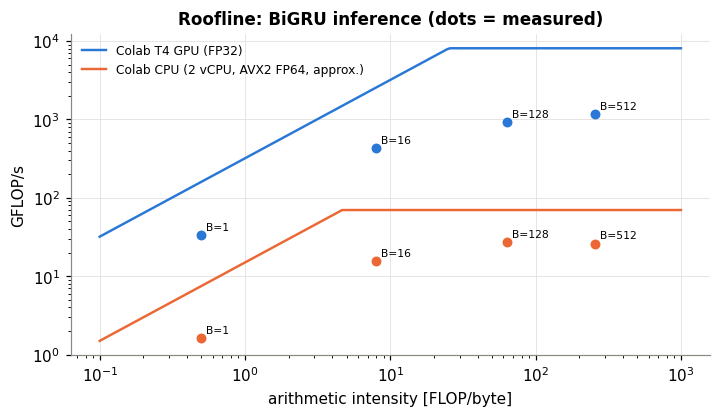

In [ ]:
# Arithmetic intensity of one GRU time step: per step the layer streams its weights (3h(i+h) floats)
# once per batch and does 2*3h(i+h) FLOPs per sample -> intensity ~ 2B/4 = B/2 FLOP/byte (float32).
I = np.logspace(-1, 3, 200)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for i, (name, spec) in enumerate(profiling.DEVICES.items()):
    ax.loglog(I, profiling.roofline(I, spec["peak_gflops"], spec["bandwidth_gbs"]), color=plotting.PALETTE[i], label=name)
for _, row in perf.iterrows():
    ai = row["batch"] / 2
    ax.scatter(ai, row["achieved GFLOP/s"], color=plotting.PALETTE[0 if row["device"] == "cuda" else 1], s=30, zorder=3)
    ax.annotate(f"B={row['batch']}", (ai, row["achieved GFLOP/s"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("arithmetic intensity [FLOP/byte]"); ax.set_ylabel("GFLOP/s"); ax.legend(fontsize=8)
ax.set_title("Roofline: BiGRU inference (dots = measured)")
_ = plotting.save(fig, "05_roofline_gru")

**Interpretation.** At batch size 1 the GRU is memory- and latency-bound: the sequential recurrence over 432 steps launches many small kernels, so achieved GFLOP/s is a tiny fraction of the peak. Batching raises the arithmetic intensity (weights are reused across the batch), so throughput rises. On the CPU it rose about 20× from batch 1 to 512, and on a GPU the gain is expected to be larger (check the table from your Colab run). The recurrence is still inherently sequential in time, which keeps the achieved rate far below the T4's 8 TFLOP/s. For this project's scale (a few hundred gaps), inference takes milliseconds either way. Training is where the GPU matters: compare the training times printed in section 1 with a CPU run of the same configuration (in `QUICK` mode on a 4-core CPU, one 12-epoch BiGRU with hidden size 64 took about 9 minutes).

## 6. Export final test-period scores for notebook 06 (no choices are made from these)

In [ ]:
best_seed = CFG["seeds"][0]
best_pw = min(pinn_models, key=lambda pw: val_res[val_res.method == f"PI-BiGRU w={pw}"].rmse.mean())
final = {"BiGRU": gru_models[best_seed], f"PI-BiGRU (w={best_pw})": pinn_models[best_pw]}
test_methods = {k: (lambda y, c, m=m: m.impute(y, c.ts, c.occ)) for k, m in final.items()}
test_methods["Neural ODE"] = lambda y, c: node.impute(y, c.ts, c.occ)
test_res = bm.run_benchmark(y_te, bm.Context(ts=ts_te, occ=o_te), test_methods, **study.FINAL_PROTOCOL)
test_res["device"] = device.type
test_res.to_csv("reports/test_deep.csv", index=False)
print("written reports/test_deep.csv  (selected PI weight on validation:", best_pw, ")")
bm.summarise(test_res).round(1)

written reports/test_deep.csv  (selected PI weight on validation: 0.003 )


gap_len,1,3,6,18,36,72,144
method,,,,,,,
PI-BiGRU (w=0.003),8.7,10.0,11.3,12.2,16.0,18.1,21.4
BiGRU,8.6,10.0,11.3,12.2,16.0,18.2,21.4
Neural ODE,9.2,11.3,13.6,19.9,24.7,26.6,28.8


### Interpreting the results (check against your GPU run)
The statements below were written from the CPU `QUICK` run and the validation protocol. Re-read them against the tables above after the full GPU run, and edit any that the numbers no longer support.
* The BiGRU learns the same kind of information as the ML models (daily shape and the gap's context), but end-to-end from raw windows. Even the under-trained `QUICK` model cut the 24-h CO₂ gap error from about 49 ppm (linear) to about 28 ppm on validation, and it is the only model that also beat linear for 24-h gaps on the test period (notebook 06). The seed-to-seed spread above is the repeatability check.
* The physics-informed loss acts as a regulariser. With a building-wide occupancy proxy, the mass balance holds only approximately for this room. The `QUICK` run trains only w = 0.01. It was slightly worse than the plain BiGRU at every gap length (e.g. 11.5 vs 10.8 ppm at 10 min), and its learned parameters drifted away from the grey-box fit (g ≈ 3.3 vs 4.5, λ ≈ 0.41 vs 0.63 per hour). An earlier exploratory CPU run with w = 0.1 hurt short gaps clearly, which is why the sweep focuses on small weights. This mirrors the grey-box finding of notebook 03.
* The Neural ODE fills a gap as an initial-value problem, so its errors accumulate along the integration. In the `QUICK` run it matched linear interpolation for gaps up to 1 h but was clearly worse for long gaps than the bidirectional models, which see both sides of the gap.
* **On Colab:** save the executed notebook back to GitHub (File → Save a copy in GitHub). The cell below also copies the result CSVs and figures to `My Drive/MMA3001/results/` and downloads them as `deep_results.zip`; add those files to the repository's `reports/` folder so that notebook 06 includes the GPU results.

In [ ]:
# Colab only: keep the GPU results (the Colab disk is deleted when the session ends).
if IN_COLAB:
    import shutil, glob
    out = Path("/content/drive/MyDrive/MMA3001/results"); out.mkdir(parents=True, exist_ok=True)
    files = ["reports/test_deep.csv", "reports/val_deep.csv"] + glob.glob("reports/figures/05_*.png")
    for f in files:
        shutil.copy(f, out / Path(f).name)
    shutil.make_archive("/content/deep_results", "zip", root_dir=".", base_dir="reports")
    from google.colab import files as colab_files
    colab_files.download("/content/deep_results.zip")
    print("copied", len(files), "files to", out, "and started the download of deep_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

copied 4 files to /content/drive/MyDrive/MMA3001/results and started the download of deep_results.zip
